# 11 — Train the binary regional neural network

## Objective

Train a neural network on the labelled RGB patch features from Notebook 05, then choose an image-level defective-patch count threshold using the original training images. Save both the fitted pipeline and its threshold configuration for Notebooks 12 and 13.

## Setup and file locations

Load dependencies, the regional feature CSV and model output paths. The six RGB columns must match Notebook 05.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
RANDOM_SEED = 67

# Existing regional feature dataset generated in Notebook 05
FEATURES_PATH = Path("../data/processed/region_features.csv")

# Original training annotations for whole-image PASS/FAIL labels
TRAIN_COCO_PATH = Path(
    "../data/cleaned/train/_annotations.coco.json"
)

# Saved neural network and image failure criterion
MODEL_PATH = Path("../models/binary_region_nn.joblib")
THRESHOLD_PATH = Path("../models/binary_region_nn_threshold.json")

# Six input features used in our previous regional classifier
FEATURE_COLS = [
    "mean_r", "mean_g", "mean_b",
    "std_r", "std_g", "std_b"
]


## Load labelled regional training features

Read the patch table and separate RGB predictors from binary labels. Labels are 0 for normal and 1 for defect.

In [2]:
# Load the previously extracted 32×32 region features.
df = pd.read_csv(FEATURES_PATH)

# Separate input features from binary defect labels.
X_train = df[FEATURE_COLS]
y_train = df["label"].astype(int)

# Confirm there are no missing feature values.
assert not X_train.isnull().any().any(), \
    "Missing values detected in the input features."

# Confirm the target labels are strictly binary.
assert set(y_train.unique()) == {0, 1}, \
    "Expected binary labels containing both 0 and 1."

print(f"Training regions: {len(df):,}")
print(f"Original images: {df['image_id'].nunique()}")
print(f"Input features: {X_train.shape[1]}")

print("\nRegion label distribution:")
print(y_train.value_counts().sort_index())


Training regions: 1,300,762
Original images: 3347
Input features: 6

Region label distribution:
label
0    1235328
1      65434
Name: count, dtype: int64


## Configure the regional neural network

Use a fitted scaler followed by a ReLU network with hidden layers of 32 and 16 neurons. Early stopping reserves 15% of training patches internally; that internal split is not grouped by source image.

In [3]:

# Construct a pipeline containing feature standardisation
# followed by a fully connected neural network classifier.
nn_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        MLPClassifier(
            # Two hidden layers with 32 and 16 neurons.
            hidden_layer_sizes=(32, 16),

            # ReLU activation for the hidden layers.
            activation="relu",

            # Adam optimiser updates network weights.
            solver="adam",

            # L2 regularisation to reduce overfitting.
            alpha=0.0001,

            # Initial learning rate.
            learning_rate_init=0.001,

            # Maximum number of training epochs.
            max_iter=500,

            # Stop training when improvement becomes small.
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,

            # Fix random initialisation for reproducibility.
            random_state=RANDOM_SEED
        )
    )
])

print("Binary neural network constructed successfully.")


Binary neural network constructed successfully.


## Fit the training pipeline

Train the scaler and classifier, then report elapsed time, iteration count and final training loss.

In [4]:

import time

# Record the starting time.
start_time = time.time()

# Fit the scaler and train the neural network
# using the six RGB features and binary defect labels.
nn_pipeline.fit(X_train, y_train)

# Calculate total training time.
training_time = time.time() - start_time

# Access the trained classifier.
nn_model = nn_pipeline.named_steps["classifier"]

print("Training complete.")
print(f"Training time: {training_time:.2f} seconds")
print(f"Training epochs: {nn_model.n_iter_}")
print(f"Final training loss: {nn_model.loss_:.5f}")


Training complete.
Training time: 147.41 seconds
Training epochs: 63
Final training loss: 0.10399


## Inspect the training loss

Plot the optimisation history. Training loss alone does not measure performance on unseen images.

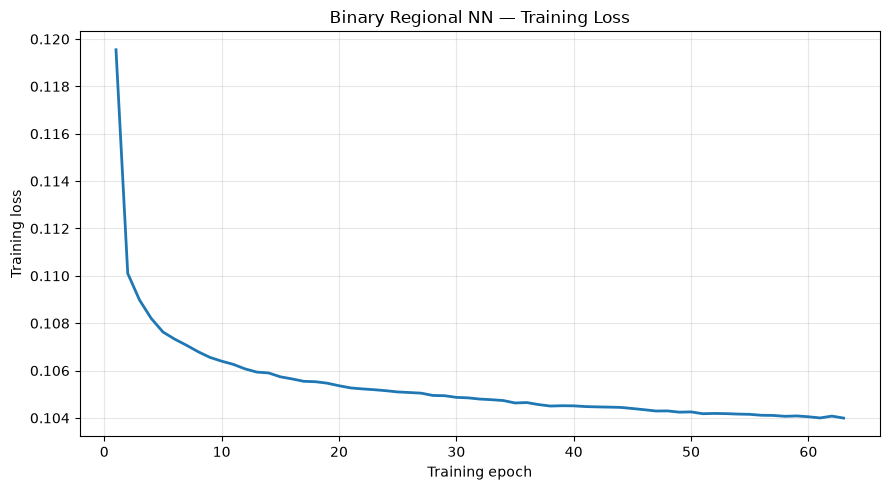

In [5]:

# Retrieve the loss recorded after each training epoch.
loss_history = nn_model.loss_curve_

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    linewidth=2
)

plt.xlabel("Training epoch")
plt.ylabel("Training loss")
plt.title("Binary Regional NN — Training Loss")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Predict the labelled training patches

Generate binary predictions on the patch table used for training. These are training diagnostics.

Region training accuracy: 95.94%
Region balanced accuracy: 64.50%

Region classification report:
              precision    recall  f1-score   support

  NON-DEFECT      0.964     0.995     0.979   1235328
      DEFECT      0.743     0.295     0.423     65434

    accuracy                          0.959   1300762
   macro avg      0.853     0.645     0.701   1300762
weighted avg      0.953     0.959     0.951   1300762



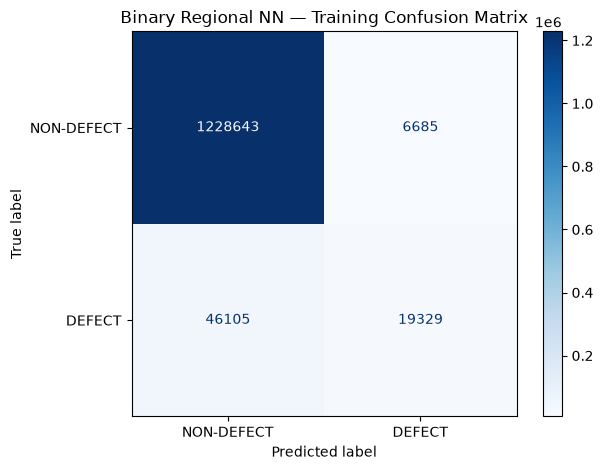

In [6]:

# Generate strict binary classifications for training regions.
# 0 = NON-DEFECT, 1 = DEFECT
y_train_pred = nn_pipeline.predict(X_train)

# Verify that the predictions contain only binary values.
assert set(np.unique(y_train_pred)).issubset({0, 1})

# Calculate training classification metrics.
train_accuracy = accuracy_score(y_train, y_train_pred)

train_balanced_accuracy = balanced_accuracy_score(
    y_train, y_train_pred
)

print(f"Region training accuracy: {train_accuracy:.2%}")
print(f"Region balanced accuracy: {train_balanced_accuracy:.2%}")

print("\nRegion classification report:")
print(
    classification_report(
        y_train,
        y_train_pred,
        labels=[0, 1],
        target_names=["NON-DEFECT", "DEFECT"],
        zero_division=0,
        digits=3
    )
)

# Generate a region-level confusion matrix.
cm = confusion_matrix(
    y_train,
    y_train_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NON-DEFECT", "DEFECT"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Binary Regional NN — Training Confusion Matrix")
plt.tight_layout()
plt.show()


## Recombine the labelled patches by source image

Count predicted defective patches for each image represented in the feature table. Ambiguous training patches were excluded when that table was built.

In [7]:

# Create a DataFrame containing the original image identifiers
# and the predicted binary classification of each region.
region_predictions_df = df[
    ["image_id", "filename"]
].copy()

# Store the neural network's binary region predictions.
region_predictions_df["predicted_defect"] = y_train_pred

# Group the region predictions by original image.
image_predictions_df = (
    region_predictions_df
    .groupby(["image_id", "filename"], as_index=False)
    .agg(
        # Sum binary predictions to count defective regions.
        predicted_defect_count=("predicted_defect", "sum"),

        # Count the total number of retained regions per image.
        total_regions=("predicted_defect", "size")
    )
)

# Calculate the proportion of retained regions classified defective.
image_predictions_df["defective_region_fraction"] = (
    image_predictions_df["predicted_defect_count"]
    / image_predictions_df["total_regions"]
)

print(
    f"Training images reconstructed: "
    f"{len(image_predictions_df)}"
)

display(image_predictions_df.head(10))


Training images reconstructed: 3347


,image_id,filename,predicted_defect_count,total_regions,defective_region_fraction
0,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,1,389,0.002571
1,1,frame_with_red_1237_jpg.rf.7c920cb9b9d7c993551...,7,390,0.017949
2,2,frame_with_red_6884_jpg.rf.73d4cccf385f78c6473...,6,390,0.015385
3,3,frame_with_red_2737_jpg.rf.8af748cd8904c67c7a0...,3,391,0.007673
4,4,frame_with_red_10465_jpg.rf.800ed5e3f0775757ce...,0,391,0.000000
5,5,frame_with_red_4731_jpg.rf.3a77f43a67d47e5af7c...,2,391,0.005115
6,6,frame_with_red_6730_jpg.rf.89f6a482f350a46b8b6...,2,389,0.005141
7,7,frame_with_red_6061_jpg.rf.82a611ae235c53956a6...,15,391,0.038363
8,8,frame_with_red_4352_jpg.rf.995114ca4546bb090eb...,27,391,0.069054
9,9,frame_with_red_6205_jpg.rf.a4b1966ef4b87fe8081...,18,387,0.046512


## Inspect predicted defect counts

Plot the distribution of defective-patch counts in this initial training-table diagnostic.

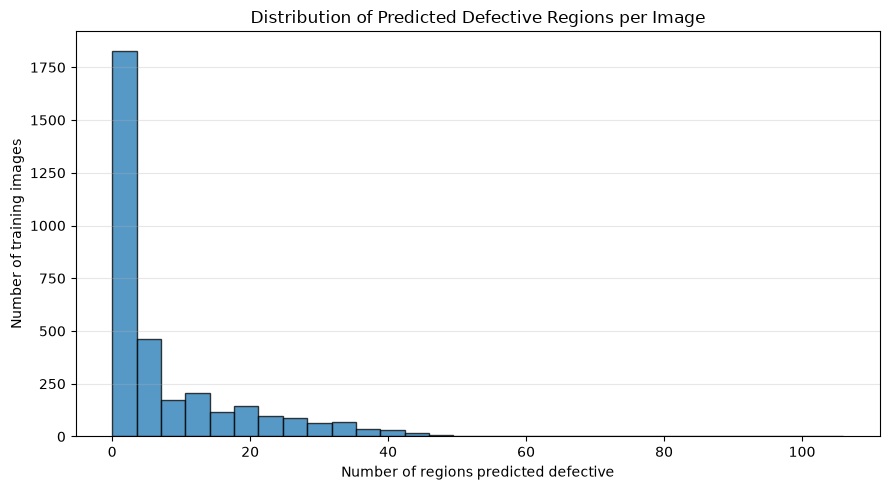

count    3347.000000
mean        7.772333
std        10.654585
min         0.000000
25%         1.000000
50%         3.000000
75%        11.000000
max       106.000000
Name: predicted_defect_count, dtype: float64


In [8]:

plt.figure(figsize=(9, 5))

# Plot how many training images contain different
# numbers of predicted defective regions.
plt.hist(
    image_predictions_df["predicted_defect_count"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.xlabel("Number of regions predicted defective")
plt.ylabel("Number of training images")
plt.title("Distribution of Predicted Defective Regions per Image")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display summary statistics.
print(
    image_predictions_df["predicted_defect_count"]
    .describe()
)


## Define full-image patch extraction

Extract all patches, including partial boundary patches, for image-level threshold selection. This later pass differs from the earlier labelled-table diagnostic.

In [9]:
# Make the project package importable when running from notebooks/.
import sys
from pathlib import Path

_SRC_PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src" / "__init__.py").is_file()
)
if str(_SRC_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_SRC_PROJECT_ROOT))

from src.patch_processing import extract_patches


## Define the six patch RGB features

Calculate RGB channel means and standard deviations using the training feature convention.

In [10]:
from src.feature_extraction import extract_region_rgb_features as extract_rgb_features


## Read original training annotations

Use annotation presence to assign image-level reference labels. Annotations establish targets; patch predictions use RGB features.

In [11]:

from PIL import Image

# Paths for original training images and annotations.
TRAIN_DIR = TRAIN_COCO_PATH.parent

# Load the training annotations.
with open(TRAIN_COCO_PATH, "r") as f:
    train_coco = json.load(f)

train_images = train_coco["images"]
train_annotations = train_coco["annotations"]

# Identify images containing at least one annotated defect.
annotated_image_ids = {
    annotation["image_id"]
    for annotation in train_annotations
}

print(f"Training images: {len(train_images)}")
print(f"Training annotations: {len(train_annotations)}")


Training images: 3347
Training annotations: 2921


## Predict every original training image

Load each image, extract its complete patch grid, predict binary patch labels and count defective patches.

In [12]:

# Store one prediction record per original training image.
training_image_records = []

for image_info in train_images:

    image_id = image_info["id"]
    filename = image_info["file_name"]

    # Load the original RGB image.
    image_path = TRAIN_DIR / filename

    with Image.open(image_path) as img:
        image = img.convert("RGB")

        # Extract all patches, including ambiguous and edge patches.
        patches = extract_patches(
            image,
            patch_size=32
        )

    # Extract the existing six RGB features for each patch.
    patch_features = pd.DataFrame([
        extract_rgb_features(patch["rgb"])
        for patch in patches
    ])[FEATURE_COLS]

    # Predict strict binary classifications for every patch.
    # 0 = NON-DEFECT, 1 = DEFECT
    patch_predictions = nn_pipeline.predict(patch_features)

    # Count the total number of predicted defective patches.
    defective_count = int(np.sum(patch_predictions))

    # Assign ground truth using the original COCO annotations.
    actual_label = int(image_id in annotated_image_ids)

    training_image_records.append({
        "image_id": image_id,
        "filename": filename,
        "total_regions": len(patches),
        "predicted_defect_count": defective_count,
        "actual_label": actual_label
    })

# Create the complete image-level training dataset.
train_image_df = pd.DataFrame(training_image_records)

print(f"Images processed: {len(train_image_df)}")

print("\nRegion counts per image:")
print(train_image_df["total_regions"].describe())

display(train_image_df.head(10))


Images processed: 3347

Region counts per image:
count    3347.0
mean      391.0
std         0.0
min       391.0
25%       391.0
50%       391.0
75%       391.0
max       391.0
Name: total_regions, dtype: float64


,image_id,filename,total_regions,predicted_defect_count,actual_label
0,0,frame_with_red_8214_jpg.rf.5acda82172bcf022bd7...,391,1,1
1,1,frame_with_red_1237_jpg.rf.7c920cb9b9d7c993551...,391,7,1
2,2,frame_with_red_6884_jpg.rf.73d4cccf385f78c6473...,391,6,1
3,3,frame_with_red_2737_jpg.rf.8af748cd8904c67c7a0...,391,3,0
4,4,frame_with_red_10465_jpg.rf.800ed5e3f0775757ce...,391,0,1
5,5,frame_with_red_4731_jpg.rf.3a77f43a67d47e5af7c...,391,2,0
6,6,frame_with_red_6730_jpg.rf.89f6a482f350a46b8b6...,391,2,1
7,7,frame_with_red_6061_jpg.rf.82a611ae235c53956a6...,391,15,1
8,8,frame_with_red_4352_jpg.rf.995114ca4546bb090eb...,391,27,1
9,9,frame_with_red_6205_jpg.rf.a4b1966ef4b87fe8081...,391,20,1


## Compare counts for PASS and FAIL images

Compare count distributions grouped by annotation-derived image labels.

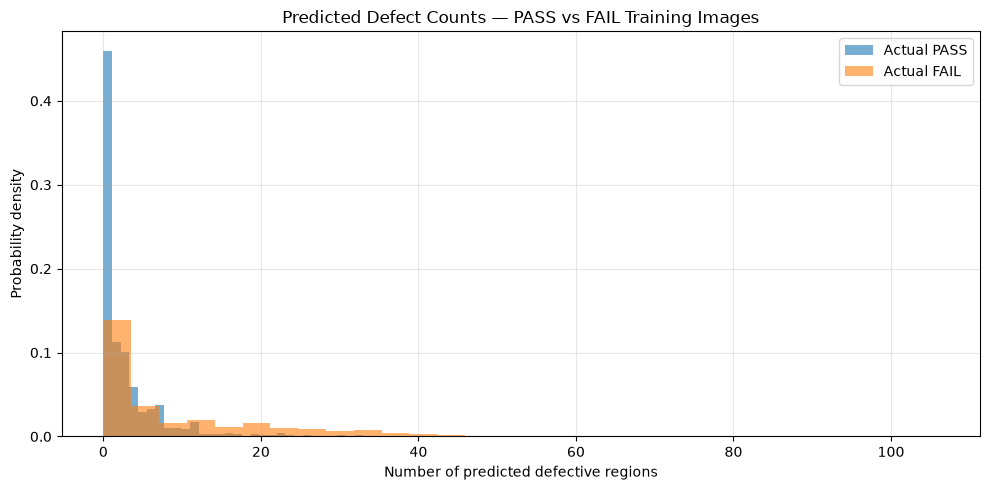

PASS images:
count    684.000000
mean       2.821637
std        4.132902
min        0.000000
25%        0.000000
50%        1.000000
75%        4.000000
max       33.000000
Name: predicted_defect_count, dtype: float64

FAIL images:
count    2663.000000
mean        9.257980
std        11.575574
min         0.000000
25%         1.000000
50%         4.000000
75%        15.000000
max       106.000000
Name: predicted_defect_count, dtype: float64


In [13]:

# Separate images by their actual COCO classification.
pass_counts = train_image_df.loc[
    train_image_df["actual_label"] == 0,
    "predicted_defect_count"
]

fail_counts = train_image_df.loc[
    train_image_df["actual_label"] == 1,
    "predicted_defect_count"
]

plt.figure(figsize=(10, 5))

# Compare predicted defective-region distributions.
plt.hist(
    pass_counts,
    bins=30,
    alpha=0.6,
    label="Actual PASS",
    density=True
)

plt.hist(
    fail_counts,
    bins=30,
    alpha=0.6,
    label="Actual FAIL",
    density=True
)

plt.xlabel("Number of predicted defective regions")
plt.ylabel("Probability density")
plt.title("Predicted Defect Counts — PASS vs FAIL Training Images")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display statistics separately for each class.
print("PASS images:")
print(pass_counts.describe())

print("\nFAIL images:")
print(fail_counts.describe())


## Search image-level count thresholds

Evaluate every integer count threshold on training images. Rank by balanced accuracy and then macro F1. An image fails only when its count is strictly greater than the threshold.

In [14]:
from sklearn.metrics import recall_score
# Test every integer count threshold from zero
# up to the maximum observed predicted defect count.
max_count = int(train_image_df["predicted_defect_count"].max())

failure_thresholds = range(0, max_count + 1)

# Actual training-image labels.
y_true = train_image_df["actual_label"]

# Store the results of each decision threshold.
threshold_results = []

for max_defects in failure_thresholds:

    # An image FAILS if the count strictly exceeds the threshold.
    y_pred = (
        train_image_df["predicted_defect_count"] > max_defects
    ).astype(int)

    threshold_results.append({
        "max_defects": max_defects,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro",
            zero_division=0
        ),
        "fail_recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "pass_recall": recall_score(
            y_true, y_pred, pos_label=0, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

# Rank thresholds by balanced accuracy and then macro F1.
ranked_thresholds = threshold_results_df.sort_values(
    ["balanced_accuracy", "macro_f1"],
    ascending=False
)

display(ranked_thresholds.head(15).round(3))


,max_defects,accuracy,balanced_accuracy,macro_f1,fail_recall,pass_recall
7,7,0.491,0.649,0.484,0.382,0.915
8,8,0.477,0.644,0.472,0.361,0.927
6,6,0.505,0.642,0.494,0.410,0.874
9,9,0.465,0.641,0.461,0.343,0.939
5,5,0.520,0.638,0.504,0.438,0.838
4,4,0.539,0.638,0.518,0.470,0.806
10,10,0.452,0.637,0.450,0.325,0.949
11,11,0.440,0.633,0.439,0.307,0.959
12,12,0.426,0.627,0.426,0.287,0.968
3,3,0.558,0.626,0.528,0.511,0.741


## Plot the threshold search and select a rule

Select the leading ranked threshold and inspect the competing metrics. These are training-based selection scores, not independent validation scores.

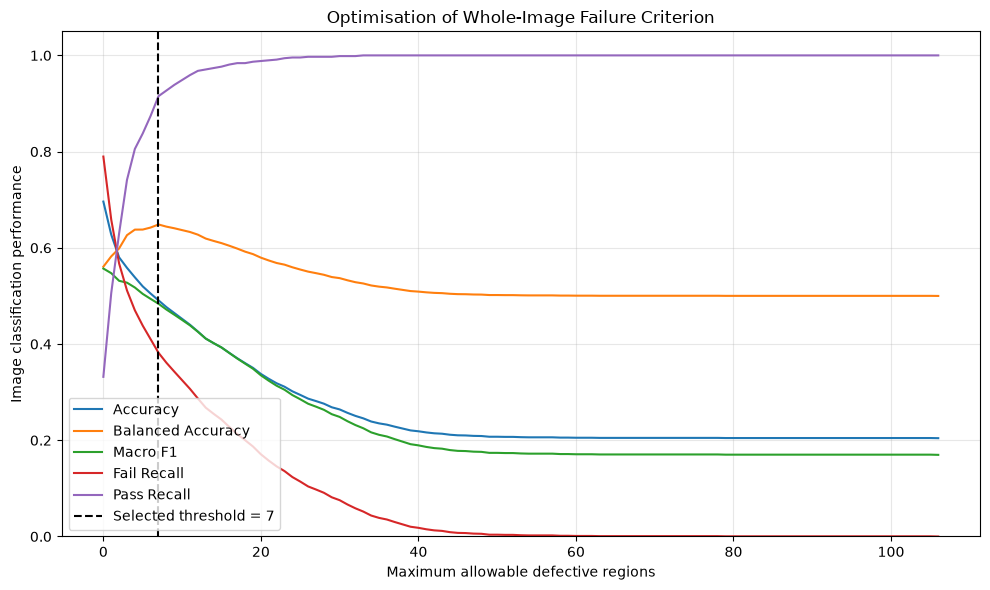

Selected defect-count threshold: 7
Training accuracy: 49.09%
Balanced accuracy: 64.86%
Macro F1: 0.484


In [15]:

plt.figure(figsize=(10, 6))

for metric in [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "fail_recall",
    "pass_recall"
]:
    plt.plot(
        threshold_results_df["max_defects"],
        threshold_results_df[metric],
        label=metric.replace("_", " ").title()
    )

# Identify the threshold giving maximum balanced accuracy.
best_result = ranked_thresholds.iloc[0]
BEST_MAX_DEFECTS = int(best_result["max_defects"])

plt.axvline(
    BEST_MAX_DEFECTS,
    linestyle="--",
    color="black",
    label=f"Selected threshold = {BEST_MAX_DEFECTS}"
)

plt.xlabel("Maximum allowable defective regions")
plt.ylabel("Image classification performance")
plt.title("Optimisation of Whole-Image Failure Criterion")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Selected defect-count threshold: {BEST_MAX_DEFECTS}")
print(f"Training accuracy: {best_result['accuracy']:.2%}")
print(f"Balanced accuracy: {best_result['balanced_accuracy']:.2%}")
print(f"Macro F1: {best_result['macro_f1']:.3f}")


## Save the pipeline and chosen threshold

Write the fitted pipeline and JSON decision settings. Notebook 13 loads both files without selecting another threshold.

In [16]:
# Create the models directory if required.
MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Save the trained neural network and its scaler.
joblib.dump(nn_pipeline, MODEL_PATH)

# Store the selected whole-image failure criterion.
threshold_config = {
    "max_defects": BEST_MAX_DEFECTS,
    "patch_size": 32,
    "selection_metric": "balanced_accuracy",
    "selection_dataset": "training",
    "region_classification": "binary"
}

# Save configuration as JSON.
with open(THRESHOLD_PATH, "w") as f:
    json.dump(threshold_config, f, indent=4)

print(f"Model saved to: {MODEL_PATH}")
print(f"Failure criterion saved to: {THRESHOLD_PATH}")
print(f"Selected maximum defects: {BEST_MAX_DEFECTS}")


Model saved to: ..\models\binary_region_nn.joblib
Failure criterion saved to: ..\models\binary_region_nn_threshold.json
Selected maximum defects: 7


## Inspect the training image confusion matrix

Display image-level training results using the chosen rule. Use Notebook 12 for validation performance.

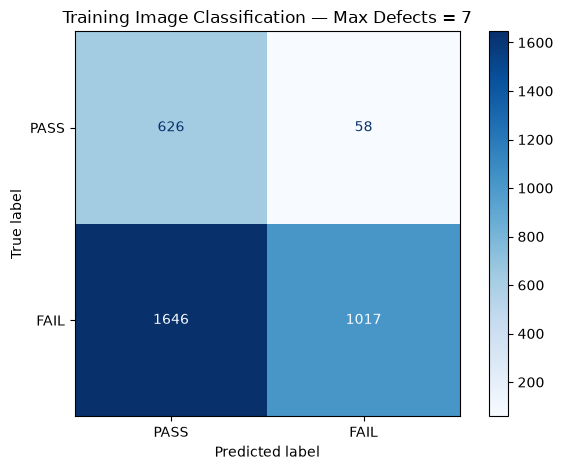

In [17]:
# Predict image-level PASS/FAIL classifications.
# 0 = PASS, 1 = FAIL.
y_true = train_image_df["actual_label"]

y_pred = (
    train_image_df["predicted_defect_count"] > BEST_MAX_DEFECTS
).astype(int)

# Calculate the confusion matrix.
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["PASS", "FAIL"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title(
    f"Training Image Classification — Max Defects = {BEST_MAX_DEFECTS}"
)

plt.tight_layout()
plt.show()


## Interpretation

Threshold selection uses training-image predictions, so its scores are optimistic estimates of generalisation. Early stopping also uses an internal patch-level split rather than an image-group split. Notebook 12 supplies the separate image-level validation evaluation. The saved threshold uses a strict greater-than comparison; equality remains PASS.